
=== Quantum Circuit (Before Measurement) ===


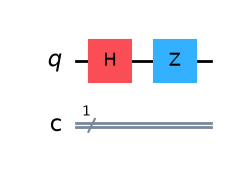


=== Statevector ===
Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))

=== Bloch Sphere Representation ===


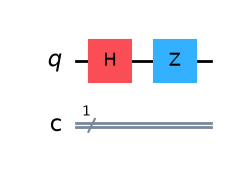

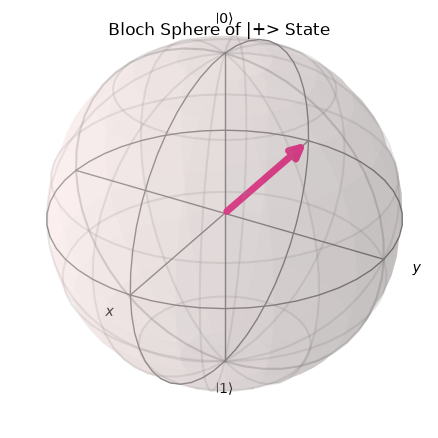


=== Q-Sphere Representation ===


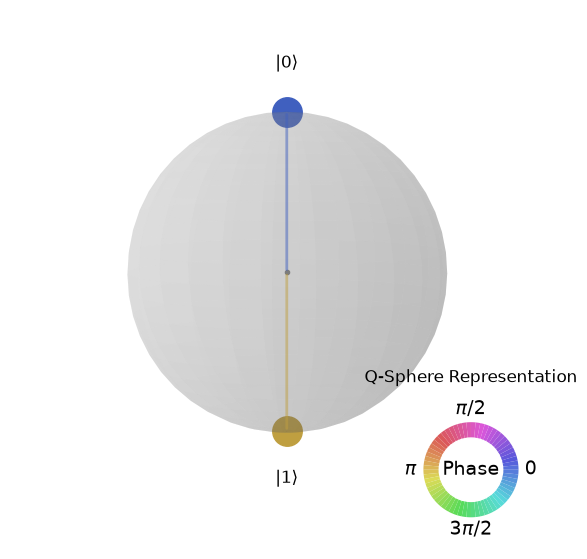


=== Quantum Circuit (With Measurement) ===


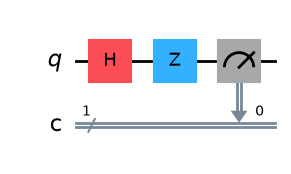


=== Measurement Results ===
{'0': 485, '1': 539}


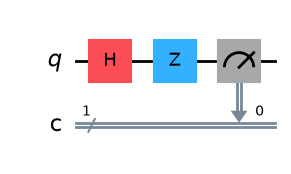

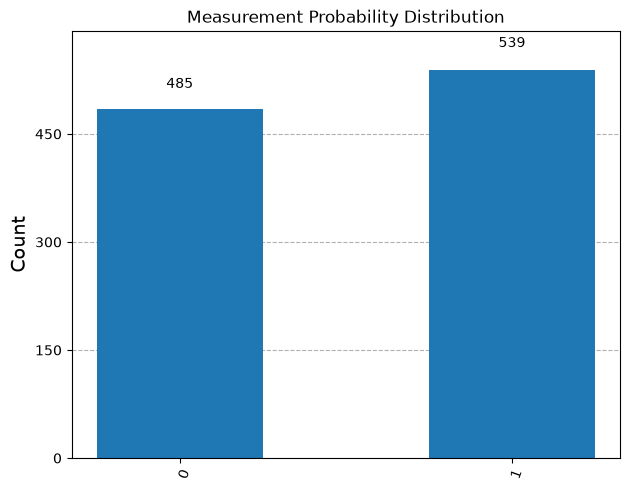

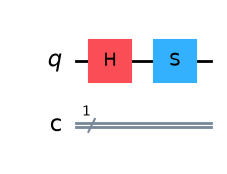

Statevector([0.70710678+0.j        , 0.        +0.70710678j],
            dims=(2,))


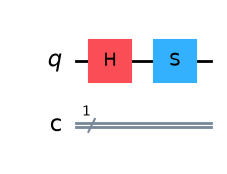

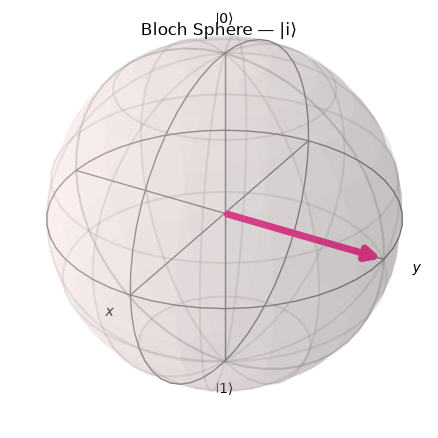

{'1': 524, '0': 500}


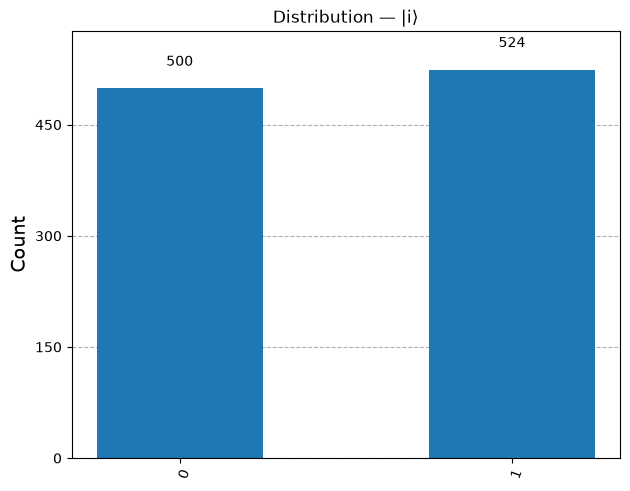

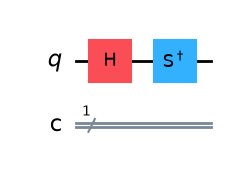

Statevector([0.70710678+0.j        , 0.        -0.70710678j],
            dims=(2,))


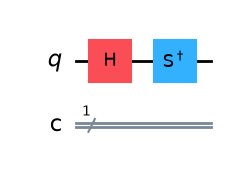

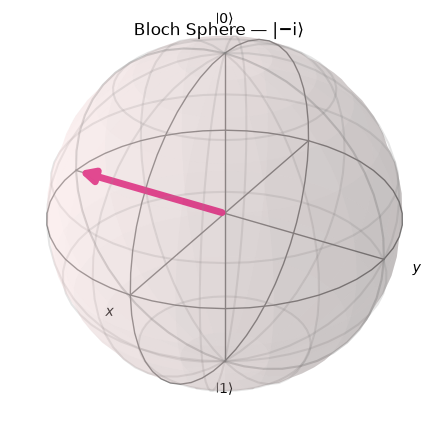

{'0': 518, '1': 506}


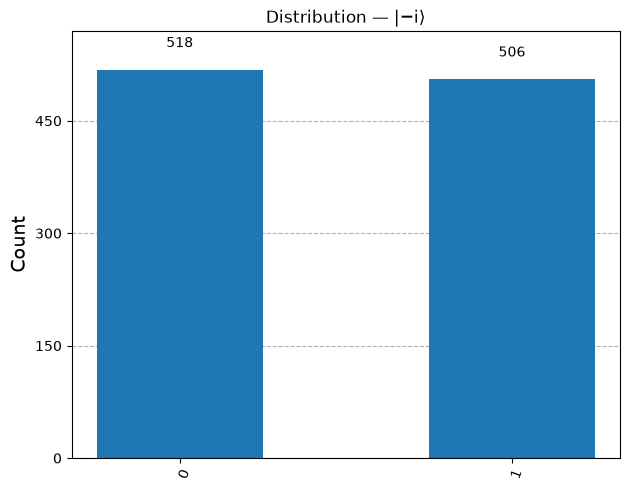

In [7]:
# ======================================================
# Qiskit Teaching Example
# Superposition + Visualization + Measurement
# ======================================================

# Enable inline plotting for Jupyter Notebook
%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector,
    plot_state_qsphere
)
from matplotlib import pyplot as plt
from IPython.display import display

# ------------------------------------------------------
# 1️⃣ Create Quantum Circuit
# ------------------------------------------------------

qc = QuantumCircuit(1, 1)

# Apply Hadamard Gate (superposition)
qc.h(0)
qc.z(0)

print("\n=== Quantum Circuit (Before Measurement) ===")
display(qc.draw("mpl"))  # Draw circuit diagram

# ------------------------------------------------------
# 2️⃣ Statevector BEFORE Measurement
# ------------------------------------------------------

state = Statevector.from_instruction(qc)

print("\n=== Statevector ===")
print(state)

# ------------------------------------------------------
# 3️⃣ Bloch Sphere Visualization
# ------------------------------------------------------

print("\n=== Bloch Sphere Representation ===")
plot_bloch_multivector(state)
plt.title("Bloch Sphere of |+> State")
plt.show()

# ------------------------------------------------------
# 4️⃣ Q-Sphere Visualization
# ------------------------------------------------------

# Requires seaborn: pip install seaborn
print("\n=== Q-Sphere Representation ===")
plot_state_qsphere(state)
plt.title("Q-Sphere Representation")
plt.show()

# ------------------------------------------------------
# 5️⃣ Add Measurement
# ------------------------------------------------------

qc.measure(0, 0)

print("\n=== Quantum Circuit (With Measurement) ===")
display(qc.draw("mpl"))

# ------------------------------------------------------
# 6️⃣ Simulation
# ------------------------------------------------------

simulator = AerSimulator()
job = simulator.run(qc, shots=1024)
result = job.result()
counts = result.get_counts()

print("\n=== Measurement Results ===")
print(counts)

# ------------------------------------------------------
# 7️⃣ Histogram
# ------------------------------------------------------

plot_histogram(counts)

plt.title("Measurement Probability Distribution")
plt.show()

# ------------------------------------------------------
# ÉTAT |i⟩  :  H puis S
# ------------------------------------------------------

qc2 = QuantumCircuit(1, 1)
qc2.h(0)
qc2.s(0)

display(qc2.draw("mpl"))

state2 = Statevector.from_instruction(qc2)
print(state2)

plot_bloch_multivector(state2)
plt.title("Bloch Sphere — |i⟩")
plt.show()

qc2.measure(0, 0)
counts2 = simulator.run(qc2, shots=1024).result().get_counts()
print(counts2)
plot_histogram(counts2)
plt.title("Distribution — |i⟩")
plt.show()

# ------------------------------------------------------
# ÉTAT |−i⟩  :  H puis S†
# ------------------------------------------------------

qc3 = QuantumCircuit(1, 1)
qc3.h(0)
qc3.sdg(0)

display(qc3.draw("mpl"))

state3 = Statevector.from_instruction(qc3)
print(state3)

plot_bloch_multivector(state3)
plt.title("Bloch Sphere — |−i⟩")
plt.show()

qc3.measure(0, 0)
counts3 = simulator.run(qc3, shots=1024).result().get_counts()
print(counts3)
plot_histogram(counts3)
plt.title("Distribution — |−i⟩")
plt.show()

